# Step 9 — 2D Laplace Equation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step09_laplace_2d.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

The [Laplace equation](https://en.wikipedia.org/wiki/Laplace%27s_equation) is the prototypical elliptic PDE. Unlike steps 1–8, it is **not** a time-dependent initial-value problem. It is a **boundary-value problem** (BVP): given boundary conditions on the domain edges, find the unique harmonic function that satisfies the equation everywhere inside.

**What you will learn:**

1. How to use the `PoissonSolver2D` spectral solver for elliptic problems
2. That a zero RHS with homogeneous Dirichlet BCs gives the trivial solution
3. How to verify the solver against a known analytical solution
4. How the DST-based spectral solver works

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

## The PDE

$$
\frac{\partial^2 \phi}{\partial x^2} + \frac{\partial^2 \phi}{\partial y^2} = 0
$$

or $\nabla^2 \phi = 0$ for short. The Laplace equation governs steady-state heat conduction (no sources), electrostatics in free space, and potential flow. It is the homogeneous form of the Poisson equation $\nabla^2 \phi = f$ we tackle in Step 10.

### Symbols

The page uses the classic letters. Everything is nondimensional, and $x$ and $y$ are the spatial coordinates (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x]$, $y \in [0, L_y]$ | spatial coordinates | $\mathbb{R}$ |
| $\phi(x, y)$ | the potential (the unknown) | $\mathbb{R}$ |
| $f(x, y)$ | right-hand side; $f = 0$ for Laplace | $\mathbb{R}$ |
| $L_x$, $L_y$ | domain lengths, both $1$ here | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior grid cells along $x$ and $y$ | count |
| $\Delta x$ | grid spacing | $\mathbb{R}_{>0}$ |
| $\phi_{j,i}$ | the potential in row $j$ and column $i$; with ghosts, $j = 0, \dots, N_{\Omega_x,y} + 1$ and $i = 0, \dots, N_{\Omega_x,x} + 1$ | $\mathbb{R}$ |
| $e_{j,i}$ | pointwise error against the exact solution | $\mathbb{R}$ |
| $\lVert e \rVert_\text{RMS}$, $\lVert e \rVert_\infty$ | root-mean-square and maximum error over the interior cells | $\mathbb{R}_{\ge 0}$ |
| $m$, $n$ | mode numbers along $x$ and $y$ | count |
| $\hat{\phi}_{mn}$, $\hat{f}_{mn}$, $\lambda_{mn}$ | spectral coefficients and Laplacian eigenvalue of mode $(m, n)$ | $\mathbb{R}$ |

## Grid layout and boundary conditions

The solved field $\phi$ lives at the T-points of [](#fig-cgrid-positions). The spectral solver operates on the **interior cells** only, and the boundary condition type determines which spectral transform is used.

**Dirichlet BCs** ($\phi = 0$ on the boundary): the DST (Discrete Sine Transform) automatically enforces zero values at the domain edges. The ghost cells follow {eq}`cgrid-dirichlet` with $c = 0$, for example $\phi_{0,i} = -\phi_{1,i}$ on the south edge.

In [2]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. The trivial case: zero RHS

With homogeneous Dirichlet boundary conditions ($\phi = 0$ on all walls) and zero right-hand side, the only solution is $\phi = 0$ everywhere. This is a sanity check for the solver.

In [4]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

num_cells = 64

# today (sesmax_core)
poisson_solver = sxt.PoissonSolver2D.create(
    nx=num_cells, ny=num_cells, Lx=1.0, Ly=1.0, bc="dirichlet"
)

grid = poisson_solver.grid
interior = (slice(1, -1), slice(1, -1))

# xᵢ = i Δx
x_position = jnp.arange(grid.Nx) * grid.dx  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_position = jnp.arange(grid.Ny) * grid.dy  # → (N_Ωx,y + 2,)
x_grid, y_grid = jnp.meshgrid(x_position, y_position)  # → G each

# f = 0
rhs_zero = jnp.zeros((grid.Ny, grid.Nx))  # → G

# today (sesmax_core)
# ∇²φ = 0
phi_trivial = poisson_solver.solve(rhs_zero)  # → G

# maxⱼᵢ |φⱼᵢ|
max_phi = jnp.max(jnp.abs(phi_trivial[interior]))  # → ()

print(f"Grid shape: ({grid.Ny}, {grid.Nx})")
print(f"Max |phi| on interior: {float(max_phi):.2e}")

Grid shape: (66, 66)
Max |phi| on interior: 0.00e+00


As expected the interior solution is machine-zero. The solver satisfies the trivial Laplace equation exactly.

## 2. Non-trivial case: manufactured solution

To test the solver on a non-trivial problem, we use the **method of manufactured solutions**. Pick an analytical solution that satisfies homogeneous Dirichlet BCs on $[0, 1]^2$:

$$
\phi_\text{exact}(x, y) = \sin(\pi x) \sin(\pi y)
$$

This vanishes on all four walls. Apply the Laplacian:

$$
\nabla^2 \phi_\text{exact} = -\pi^2 \sin(\pi x) \sin(\pi y) - \pi^2 \sin(\pi x) \sin(\pi y) = -2 \pi^2 \sin(\pi x) \sin(\pi y)
$$

So we solve $\nabla^2 \phi = f$ with $f = -2 \pi^2 \sin(\pi x) \sin(\pi y)$ and check that the numerical solution matches $\phi_\text{exact}$. The error is measured on the interior cells by the root-mean-square and the maximum,

$$
\lVert e \rVert_\text{RMS} = \left( \frac{1}{N_{\Omega_x,x} N_{\Omega_x,y}} \sum_{j=1}^{N_{\Omega_x,y}} \sum_{i=1}^{N_{\Omega_x,x}} e_{j,i}^2 \right)^{1/2}
$$

$$
\lVert e \rVert_\infty = \max_{j,i} \vert e_{j,i} \vert
$$

The code and its printed output call the first one the "L2 error".

> Strictly speaking this is a Poisson equation (non-zero RHS). The key point is that the *solver* is the same — the Laplace equation is just the special case $f = 0$.

In [5]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# sin(π x)
sin_x = jnp.sin(jnp.pi * x_grid)  # → G
# sin(π y)
sin_y = jnp.sin(jnp.pi * y_grid)  # → G
# f = −2 π² sin(π x) sin(π y)
rhs_manufactured = -2.0 * jnp.pi**2 * sin_x * sin_y  # → G

# today (sesmax_core)
# ∇²φ = f
phi_numerical = poisson_solver.solve(rhs_manufactured)  # → G

# φ_exact = sin(π x) sin(π y)
phi_exact = sin_x * sin_y  # → G

# eⱼᵢ = φⱼᵢ − φ_exactⱼᵢ on the interior
error = phi_numerical[interior] - phi_exact[interior]  # → N_Ωx,y × N_Ωx,x
# ‖e‖_RMS = (mean e²)^½
rms_error = float(jnp.sqrt(jnp.mean(error**2)))
# ‖e‖_∞ = maxⱼᵢ |eⱼᵢ|
max_error = float(jnp.max(jnp.abs(error)))

print(f"L2  error (interior): {rms_error:.6e}")
print(f"Linf error (interior): {max_error:.6e}")

L2  error (interior): 1.003862e-04
Linf error (interior): 2.007484e-04


## 3. Visualise solution and error

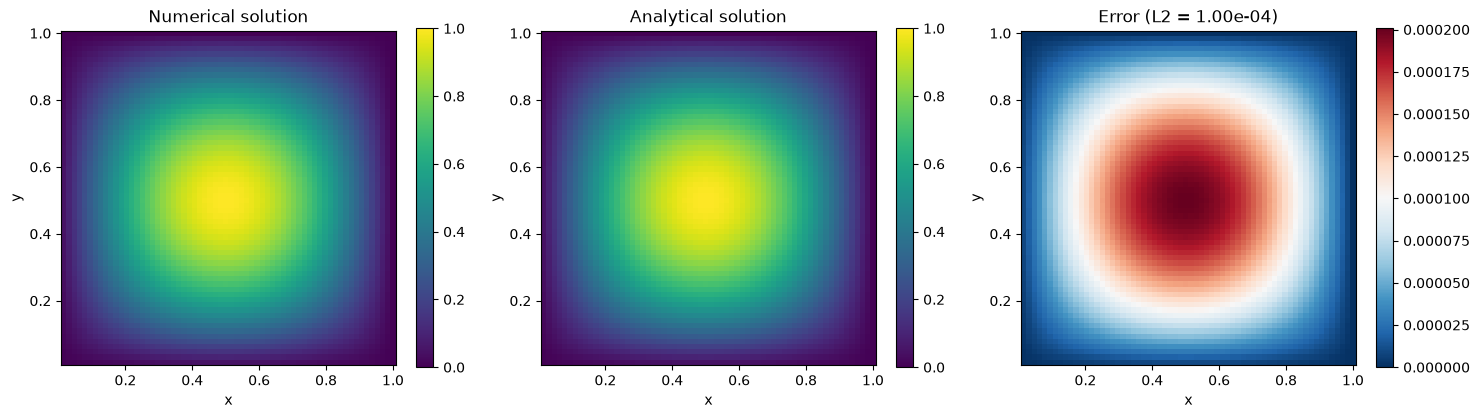

In [6]:
panels = [
    (phi_numerical[interior], "Numerical solution", None),
    (phi_exact[interior], "Analytical solution", None),
    (error, f"Error (L2 = {rms_error:.2e})", "RdBu_r"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (field, title, colormap) in zip(axes, panels, strict=True):
    mesh = ax.pcolormesh(
        x_grid[interior], y_grid[interior], field, shading="auto", cmap=colormap
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    plt.colorbar(mesh, ax=ax)

plt.tight_layout()
plt.show()

## 4. Higher-mode test

The DST solver handles any combination of Fourier modes. Let us test a higher-mode solution $\phi = \sin(2 \pi x) \sin(3 \pi y)$ whose Laplacian is $-\pi^2 (4 + 9) \sin(2 \pi x) \sin(3 \pi y) = -13 \pi^2 \sin(2 \pi x) \sin(3 \pi y)$.

Higher-mode L2 error: 7.496414e-04


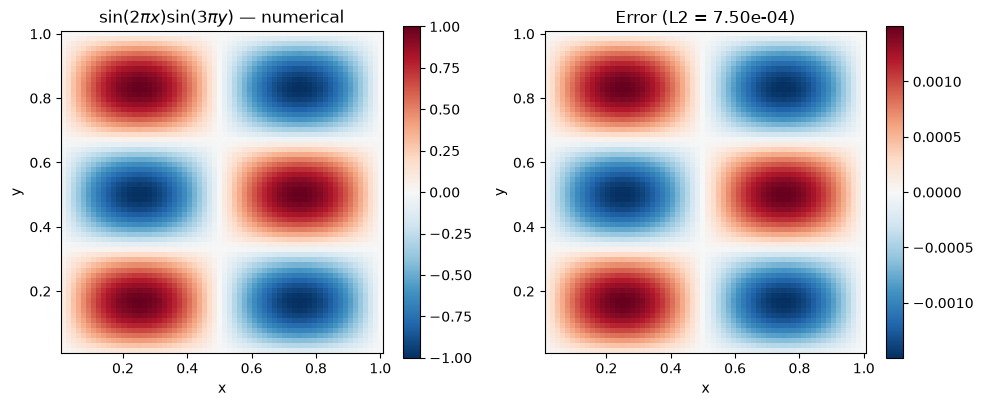

In [7]:
# Shapes: N_Ωx,x = 64, N_Ωx,y = 64 interior cells;
# I = N_Ωx,y × N_Ωx,x interior cells
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# sin(2π x)
sin_2x = jnp.sin(2.0 * jnp.pi * x_grid)  # → G
# sin(3π y)
sin_3y = jnp.sin(3.0 * jnp.pi * y_grid)  # → G
# f = −13 π² sin(2π x) sin(3π y)
rhs_high_mode = -13.0 * jnp.pi**2 * sin_2x * sin_3y  # → G

# today (sesmax_core)
# ∇²φ = f
phi_high_mode = poisson_solver.solve(rhs_high_mode)  # → G
# φ_exact = sin(2π x) sin(3π y)
exact_high_mode = sin_2x * sin_3y  # → G

# eⱼᵢ = φⱼᵢ − φ_exactⱼᵢ on the interior
error_high_mode = phi_high_mode[interior] - exact_high_mode[interior]  # → I
# ‖e‖_RMS = (mean e²)^½
rms_error_high_mode = float(jnp.sqrt(jnp.mean(error_high_mode**2)))
print(f"Higher-mode L2 error: {rms_error_high_mode:.6e}")

panels = [
    (
        phi_high_mode[interior],
        r"$\sin(2\pi x)\sin(3\pi y)$ — numerical",
    ),
    (error_high_mode, f"Error (L2 = {rms_error_high_mode:.2e})"),
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (field, title) in zip(axes, panels, strict=True):
    mesh = ax.pcolormesh(
        x_grid[interior], y_grid[interior], field, shading="auto", cmap="RdBu_r"
    )
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    plt.colorbar(mesh, ax=ax)

plt.tight_layout()
plt.show()

## 5. Convergence with grid refinement

We verify that the solver converges as $O(\Delta x^2)$ by solving the same manufactured problem at increasing resolution.

n=  16  L2 error = 1.609442e-03


n=  32  L2 error = 4.017349e-04
n=  64  L2 error = 1.003862e-04


n= 128  L2 error = 2.509205e-05


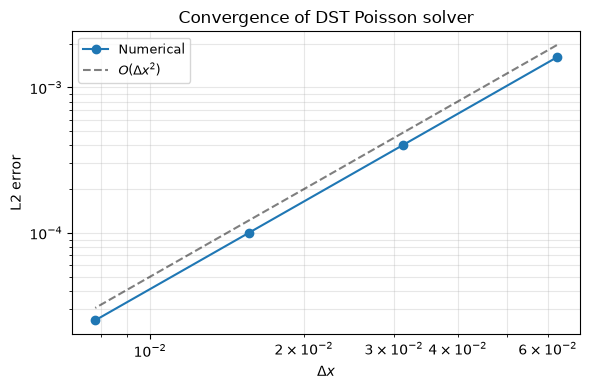

In [8]:
# Shapes: N_Ωx,x = N_Ωx,y = n interior cells for n in resolutions;
# (n + 2) × (n + 2) with the ghosts

resolutions = [16, 32, 64, 128]
rms_errors = []

for n in resolutions:
    # today (sesmax_core)
    solver_n = sxt.PoissonSolver2D.create(nx=n, ny=n, Lx=1.0, Ly=1.0, bc="dirichlet")
    # xᵢ = i Δx
    x_n = jnp.arange(solver_n.grid.Nx) * solver_n.grid.dx  # → (n + 2,)
    # yⱼ = j Δy
    y_n = jnp.arange(solver_n.grid.Ny) * solver_n.grid.dy  # → (n + 2,)
    x_grid_n, y_grid_n = jnp.meshgrid(x_n, y_n)  # → (n + 2, n + 2) each
    # sin(π x), sin(π y)
    sin_x_n = jnp.sin(jnp.pi * x_grid_n)  # → (n + 2, n + 2)
    sin_y_n = jnp.sin(jnp.pi * y_grid_n)  # → (n + 2, n + 2)
    # f = −2 π² sin(π x) sin(π y)
    rhs_n = -2.0 * jnp.pi**2 * sin_x_n * sin_y_n  # → (n + 2, n + 2)
    # φ_exact = sin(π x) sin(π y)
    exact_n = sin_x_n * sin_y_n  # → (n + 2, n + 2)
    # today (sesmax_core)
    # ∇²φ = f
    phi_n = solver_n.solve(rhs_n)  # → (n + 2, n + 2)
    # eⱼᵢ = φⱼᵢ − φ_exactⱼᵢ on the interior
    error_n = phi_n[interior] - exact_n[interior]  # → (n, n)
    # ‖e‖_RMS = (mean e²)^½
    rms_error_n = float(jnp.sqrt(jnp.mean(error_n**2)))
    rms_errors.append(rms_error_n)
    print(f"n={n:4d}  L2 error = {rms_error_n:.6e}")

dx_values = [1.0 / n for n in resolutions]

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(dx_values, rms_errors, "o-", label="Numerical")
ax.loglog(
    dx_values,
    [0.5 * dx**2 for dx in dx_values],
    "k--",
    alpha=0.5,
    label=r"$O(\Delta x^2)$",
)
ax.set_xlabel(r"$\Delta x$")
ax.set_ylabel("L2 error")
ax.set_title("Convergence of DST Poisson solver")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## 6. How the DST solver works

Under the hood, `PoissonSolver2D` with `bc="dirichlet"` uses the **Discrete Sine Transform** (DST). The idea:

1. **Eigenfunction expansion.** The eigenfunctions of the Laplacian on $[0, L_x]$ with homogeneous Dirichlet BCs are $\sin(m \pi x / L_x)$. In 2D the eigenfunctions are products $\sin(m \pi x / L_x) \sin(n \pi y / L_y)$.

2. **Transform to spectral space.** The DST decomposes both the RHS $f$ and the unknown $\phi$ into these eigenfunctions.

3. **Algebraic solve.** In spectral space the Laplacian is diagonal: each mode $(m, n)$ satisfies the first equation below, with the eigenvalue in the second.

$$
\hat{\phi}_{mn} = \frac{\hat{f}_{mn}}{\lambda_{mn}}
$$

$$
\lambda_{mn} = -\pi^2 \left( \frac{m^2}{L_x^2} + \frac{n^2}{L_y^2} \right)
$$

4. **Transform back.** An inverse DST returns $\phi$ on the physical grid.

The result is an **exact** solve (up to floating-point arithmetic) with $O(N_{\Omega_x,x} N_{\Omega_x,y} \log(N_{\Omega_x,x} N_{\Omega_x,y}))$ cost — far cheaper than iterative methods for these structured grids.

## 7. Summary

| Concept | API |
|---------|-----|
| Create solver | `PoissonSolver2D.create(nx, ny, Lx, Ly, bc="dirichlet")` |
| Grid coordinates | `x_position = jnp.arange(grid.Nx) * grid.dx` |
| Solve Laplace ($f = 0$) | `poisson_solver.solve(jnp.zeros(...))` |
| Solve Poisson | `poisson_solver.solve(rhs)` |
| Spectral method | DST (Dirichlet), DCT (Neumann), FFT (periodic) |

**Key takeaway:** Elliptic solves are **not** time-stepping. You call `poisson_solver.solve(rhs)` once and get the steady-state answer.

**Next:** [Step 10](step10_poisson_2d.ipynb) explores the full Poisson equation with multiple boundary conditions and convergence analysis.